# Predicting Loan Payback — Modeling

## Step 0 · Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from lightgbm import LGBMClassifier

pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

DATA_DIR = Path("data")
FIG_DIR = Path("reports")
TARGET = "loan_paid_back"

## Step 1 · Load cleaned data

In [2]:
train = pd.read_csv(DATA_DIR / "train_clean.csv")
test = pd.read_csv(DATA_DIR / "test_clean.csv")

y = train[TARGET]
print("train:", train.shape, " test:", test.shape)
print("repaid rate:", round(y.mean() * 100, 2), "%")

train: (593994, 16)  test: (254569, 15)
repaid rate: 79.88 %


**Important: what this data can and cannot tell us**
- Every row is a loan that was **already approved and funded**; we only see whether it was paid back.
- Declined applicants are not in the data, so the model learns **which approved borrowers are more likely to default** — not whether a new applicant should have been approved.
- This is the classic **reject-inference** limitation of credit models. All results below are framed as ranking and tiering the lender's approved loans.

## Step 2 · Choose features for each model

In [3]:
# Logistic regression: log-transformed numbers, credit_score (not grade, r = -0.91), no gender
LR_NUM = ["log_annual_income", "log_debt_to_income_ratio", "credit_score", "loan_amount", "interest_rate"]
LR_CAT = ["marital_status", "education_level", "employment_status", "loan_purpose"]

# LightGBM: trees are not hurt by correlated features or skew, so keep grade too; still no gender
GBM_NUM = ["annual_income", "debt_to_income_ratio", "credit_score", "loan_amount", "interest_rate", "grade_ordinal"]
GBM_CAT = ["marital_status", "education_level", "employment_status", "loan_purpose"]

print("Logistic regression features:", len(LR_NUM + LR_CAT))
print("LightGBM features:", len(GBM_NUM + GBM_CAT))

Logistic regression features: 9
LightGBM features: 10


**Interpretation**
- Gender is excluded from both models: it barely changes payback (79.5%–80.2%) and should not drive credit decisions.
- Logistic regression keeps only credit score because credit score and grade are highly correlated (r = −0.91).
- LightGBM keeps grade as well, because tree models are not hurt by correlated features.

## Step 3 · Cross-validation setup

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "recall_not_repaid": make_scorer(recall_score, pos_label=0),
    "brier": "neg_brier_score",
}

results = []


def evaluate(name, model, X):
    scores = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    row = {
        "model": name,
        "roc_auc": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
        "accuracy": scores["test_accuracy"].mean(),
        "recall_not_repaid": scores["test_recall_not_repaid"].mean(),
        "brier_score": -scores["test_brier"].mean(),
    }
    results.append(row)
    return pd.DataFrame([row]).round(4)

**Interpretation**
- Stratified 5-fold CV keeps the 80/20 split in every fold; each row is used for validation exactly once.
- **ROC AUC** (main metric, also the Kaggle metric): how well the model ranks borrowers who repay above those who default. 0.5 = random, 1 = perfect.
- `recall_not_repaid`: share of loans that were **not** repaid that the model flags (at the default 0.5 threshold).
- **Brier score** = the mean squared error between the predicted probability and the actual 0/1 outcome — the classification version of the **MSE** used for linear regression in class. Lower is better; it checks whether the probabilities themselves are accurate, not just the ranking.
- MSE itself is not used: the target is 0/1, so this is a classification problem, not a regression problem.

## Step 4 · Baseline

In [5]:
baseline = DummyClassifier(strategy="most_frequent")
display(evaluate("Baseline (always 'repaid')", baseline, train[LR_NUM + LR_CAT]))

,model,roc_auc,roc_auc_std,accuracy,recall_not_repaid,brier_score
0,Baseline (always 'repaid'),0.5,0.0,0.7988,0.0,0.2012


**Interpretation**
- The baseline ignores every feature and always predicts "repaid".
- It gets ~79.9% accuracy only because most borrowers repay, but ROC AUC is 0.5 (random) and it catches 0% of defaults.
- Every real model must beat this floor.

### Company baselines: the lender's grade and a classic scorecard

In [6]:
grade_baseline = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), ["grade_ordinal"])])),
    ("model", LogisticRegression()),
])
display(evaluate("Company baseline: lender's grade only", grade_baseline, train[["grade_ordinal"]]))

SCORECARD_COLS = ["credit_score", "log_debt_to_income_ratio"]
scorecard = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), SCORECARD_COLS)])),
    ("model", LogisticRegression()),
])
display(evaluate("Classic scorecard: credit score + DTI", scorecard, train[SCORECARD_COLS]))

,model,roc_auc,roc_auc_std,accuracy,recall_not_repaid,brier_score
0,Company baseline: lender's grade only,0.6549,0.0018,0.796,0.0179,0.154


,model,roc_auc,roc_auc_std,accuracy,recall_not_repaid,brier_score
0,Classic scorecard: credit score + DTI,0.7678,0.0018,0.8099,0.1931,0.1353


**Interpretation**
- The dataset does not describe the lender's current model, but `grade_subgrade` is the lender's own risk grade and closely follows credit score (r = −0.91). I use it as the **company's existing baseline**.
- The **classic scorecard** uses the two checks most lenders start with — credit score and debt-to-income — to represent a typical non-ML underwriting approach.
- Any ML model has to beat these, not just the Dummy baseline, to be worth adopting.

## Step 5 · Logistic regression

In [7]:
lr_prep = ColumnTransformer([
    ("num", StandardScaler(), LR_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), LR_CAT),
])

logreg = Pipeline([
    ("prep", lr_prep),
    ("model", LogisticRegression(max_iter=1000)),
])

display(evaluate("Logistic regression", logreg, train[LR_NUM + LR_CAT]))

,model,roc_auc,roc_auc_std,accuracy,recall_not_repaid,brier_score
0,Logistic regression,0.9081,0.0008,0.9,0.5979,0.0769


**Interpretation**
- The scaler and encoder sit inside the pipeline, so in every fold they are fitted on the training part only — no data leakage.
- ROC AUC jumps from 0.50 (baseline) and 0.65 (lender's grade) to **0.908**, and the model now flags **59.8%** of loans that were not repaid.
- Results are very stable across folds (AUC std 0.0008).

### What drives risk? Logistic regression coefficients

In [8]:
logreg.fit(train[LR_NUM + LR_CAT], y)

names = logreg.named_steps["prep"].get_feature_names_out()
coefs = logreg.named_steps["model"].coef_[0]

coef_table = pd.DataFrame({"feature": names, "coefficient": coefs})
coef_table["feature"] = coef_table["feature"].str.replace("num__", "").str.replace("cat__", "")
coef_table["odds_ratio"] = np.exp(coef_table["coefficient"])
coef_table = coef_table.sort_values("coefficient")

display(coef_table.round(3))

,feature,coefficient,odds_ratio
18,employment_status_Unemployed,-3.919,0.020
17,employment_status_Student,-2.235,0.107
1,log_debt_to_income_ratio,-0.991,0.371
4,interest_rate,-0.054,0.948
3,loan_amount,-0.004,0.996
22,loan_purpose_Education,0.005,1.005
24,loan_purpose_Medical,0.018,1.018
0,log_annual_income,0.023,1.024
21,loan_purpose_Debt consolidation,0.071,1.073
9,education_level_Bachelor's,0.100,1.105


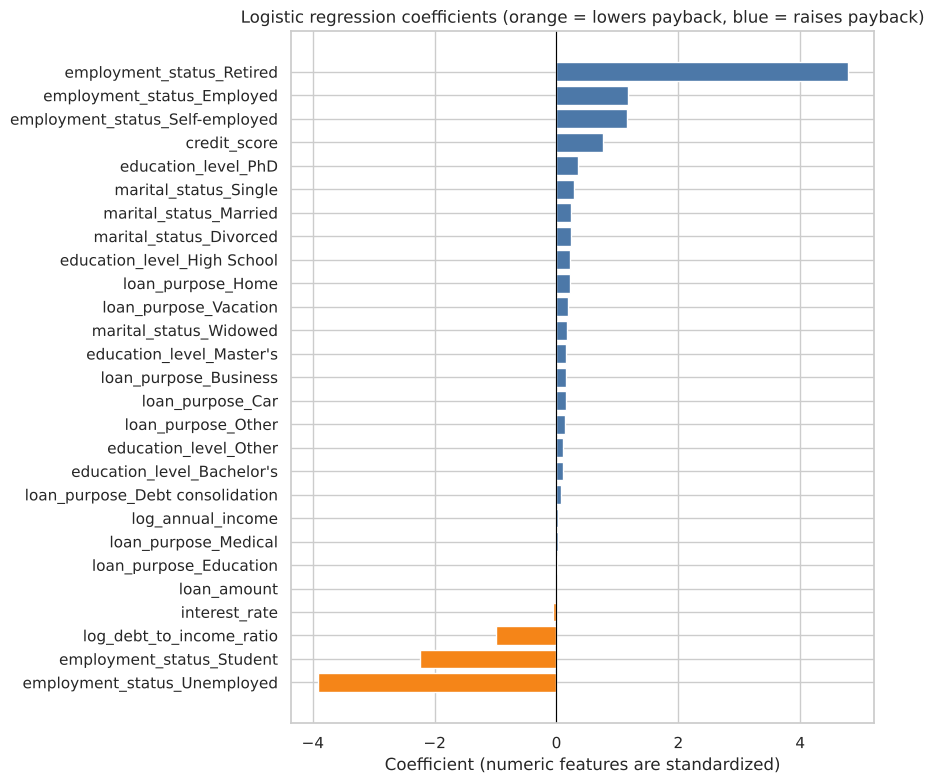

In [9]:
plt.figure(figsize=(9, 8))
colors = ["#F58518" if c < 0 else "#4C78A8" for c in coef_table["coefficient"]]
plt.barh(coef_table["feature"], coef_table["coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic regression coefficients (orange = lowers payback, blue = raises payback)")
plt.xlabel("Coefficient (numeric features are standardized)")
plt.tight_layout()
plt.savefig(FIG_DIR / "logreg_coefficients.png", dpi=120)
plt.show()

**How to read**
- A **negative** coefficient lowers the odds of repayment (higher risk); a **positive** one raises them.
- Numeric features are standardized, so their coefficients mean "effect of a one-standard-deviation increase".
- Category coefficients are relative to the other levels of the same feature.
- `odds_ratio` = e^coefficient: e.g., 0.5 means the odds of repayment are cut in half.

**Interpretation**
- **Employment status dominates:** unemployed (coef −3.92) and student (−2.24) borrowers have far lower odds of repaying; retired borrowers have the highest (+4.78).
- **DTI is the strongest numeric risk factor:** one standard deviation higher log DTI cuts the odds of repayment to about 0.37×.
- **Credit score protects:** one standard deviation higher score roughly doubles the odds of repayment (odds ratio 2.14).
- Interest rate, loan amount, and income have small coefficients once the other features are included; marital status, education, and loan purpose have only small effects.

## Step 6 · LightGBM

In [10]:
X_gbm = train[GBM_NUM + GBM_CAT].copy()
for col in GBM_CAT:
    X_gbm[col] = X_gbm[col].astype("category")

lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbose=-1,
)

display(evaluate("LightGBM", lgbm, X_gbm))

,model,roc_auc,roc_auc_std,accuracy,recall_not_repaid,brier_score
0,LightGBM,0.9215,0.0007,0.9057,0.6088,0.0717


**Interpretation**
- LightGBM handles categories directly (no one-hot needed) and can learn nonlinear patterns such as the DTI threshold found in EDA.
- It reaches ROC AUC **0.9215**, higher than logistic regression (0.908), and flags **60.9%** of loans that were not repaid.

### Feature importance

,feature,share_%
8,employment_status,68.53
1,debt_to_income_ratio,19.30
2,credit_score,8.59
5,grade_ordinal,1.61
3,loan_amount,0.69
0,annual_income,0.58
4,interest_rate,0.50
9,loan_purpose,0.10
7,education_level,0.06
6,marital_status,0.02


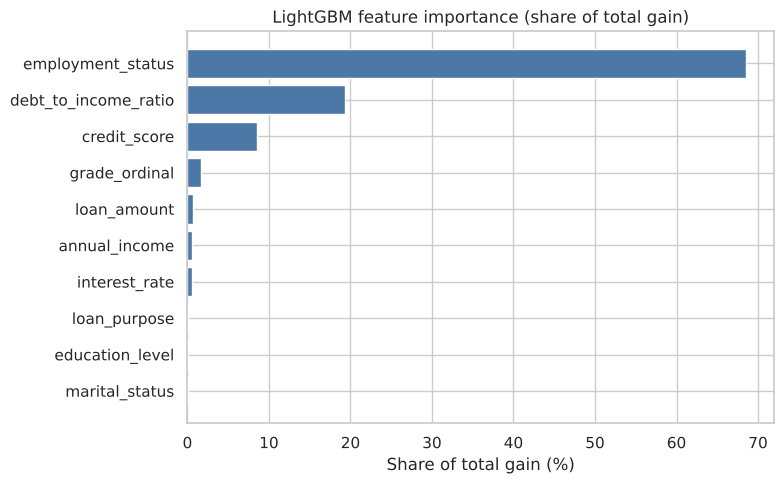

In [11]:
lgbm.fit(X_gbm, y)

importance = pd.DataFrame({
    "feature": X_gbm.columns,
    "importance": lgbm.booster_.feature_importance(importance_type="gain"),
})
importance["share_%"] = importance["importance"] / importance["importance"].sum() * 100
importance = importance.sort_values("share_%", ascending=False)

display(importance[["feature", "share_%"]].round(2))

plt.figure(figsize=(8, 5))
plt.barh(importance["feature"][::-1], importance["share_%"][::-1], color="#4C78A8")
plt.title("LightGBM feature importance (share of total gain)")
plt.xlabel("Share of total gain (%)")
plt.tight_layout()
plt.savefig(FIG_DIR / "lgbm_feature_importance.png", dpi=120)
plt.show()

**How to read**
- "Gain" measures how much each feature improves the model's splits, summed over all trees.
- Compare the top features with the EDA findings and with the logistic regression coefficients.

**Interpretation**
- Three features carry over 96% of the gain: **employment status (68.5%)**, **DTI (19.3%)**, and **credit score (8.6%)**.
- Grade adds only 1.6% once credit score is included, confirming they carry the same information (r = −0.91).
- Both models agree on the top three risk factors.

## Step 7 · Model comparison

In [12]:
comparison = pd.DataFrame(results).round(4)
display(comparison)
comparison.to_csv(FIG_DIR / "model_comparison.csv", index=False)

,model,roc_auc,roc_auc_std,accuracy,recall_not_repaid,brier_score
0,Baseline (always 'repaid'),0.5000,0.0000,0.7988,0.0000,0.2012
1,Company baseline: lender's grade only,0.6549,0.0018,0.7960,0.0179,0.1540
2,Classic scorecard: credit score + DTI,0.7678,0.0018,0.8099,0.1931,0.1353
3,Logistic regression,0.9081,0.0008,0.9000,0.5979,0.0769
4,LightGBM,0.9215,0.0007,0.9057,0.6088,0.0717


**Interpretation**

| Model | ROC AUC | Recall (not repaid) | Brier score |
|---|---|---|---|
| Baseline (always "repaid") | 0.500 | 0% | 0.201 |
| Lender's grade only | 0.655 | 1.8% | 0.154 |
| Classic scorecard (credit score + DTI) | 0.768 | 19.3% | 0.135 |
| Logistic regression | 0.908 | 59.8% | 0.077 |
| **LightGBM** | **0.922** | **60.9%** | **0.072** |

- **LightGBM is the best model on every metric.** Its AUC is 0.27 higher than the lender's grade and 0.15 higher than the classic scorecard.
- The **Brier score** (MSE for probabilities) falls from 0.154 (lender's grade) to 0.072 (LightGBM): the predicted probabilities are also much more accurate, not just the ranking.
- Accuracy barely separates the models (0.80 – 0.91), which is why accuracy is not the main metric for imbalanced data.
- LightGBM is chosen as the **challenger model** for the business analysis below.

## Step 7b · Business impact: defaulted principal if the lender kept only its safest approved loans

In [13]:
from sklearn.model_selection import train_test_split

train_idx, val_idx = train_test_split(train.index, test_size=0.2, stratify=y, random_state=42)

lgbm_val = LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31, random_state=42, verbose=-1)
lgbm_val.fit(X_gbm.loc[train_idx], y.loc[train_idx])
scorecard.fit(train.loc[train_idx, SCORECARD_COLS], y.loc[train_idx])

val = train.loc[val_idx, [TARGET, "loan_amount", "grade_ordinal"]].copy()
val["score_grade"] = -val["grade_ordinal"]                       # better grade = higher score
val["score_scorecard"] = scorecard.predict_proba(train.loc[val_idx, SCORECARD_COLS])[:, 1]
val["score_lgbm"] = lgbm_val.predict_proba(X_gbm.loc[val_idx])[:, 1]

rankers = {
    "Lender's grade": "score_grade",
    "Classic scorecard": "score_scorecard",
    "LightGBM": "score_lgbm",
}
all_defaults = (val[TARGET] == 0).sum()

rows = []
for keep in [0.7, 0.8, 0.9]:
    n_keep = int(len(val) * keep)
    for name, col in rankers.items():
        kept = val.sort_values(col, ascending=False, kind="mergesort").head(n_keep)
        defaulted = kept[TARGET] == 0
        rows.append({
            "share_kept": f"{keep:.0%}",
            "ranked_by": name,
            "default_rate_%": round(defaulted.mean() * 100, 1),
            "defaulted_principal_$M": round(kept.loc[defaulted, "loan_amount"].sum() / 1e6, 1),
            "share_of_all_defaults_kept_%": round(defaulted.sum() / all_defaults * 100, 1),
        })

impact = pd.DataFrame(rows)
display(impact)
impact.to_csv(FIG_DIR / "business_impact.csv", index=False)
print(f"Validation set: {len(val):,} approved loans, {all_defaults:,} defaults")

,share_kept,ranked_by,default_rate_%,defaulted_principal_$M,share_of_all_defaults_kept_%
0,70%,Lender's grade,15.1,188.6,52.6
1,70%,Classic scorecard,11.1,141.3,38.8
2,70%,LightGBM,4.7,59.9,16.5
3,80%,Lender's grade,17.0,242.0,67.4
4,80%,Classic scorecard,13.3,190.6,52.7
5,80%,LightGBM,6.8,97.1,26.8
6,90%,Lender's grade,18.3,294.4,81.9
7,90%,Classic scorecard,16.1,259.8,72.2
8,90%,LightGBM,11.5,185.2,51.5


Validation set: 118,799 approved loans, 23,900 defaults


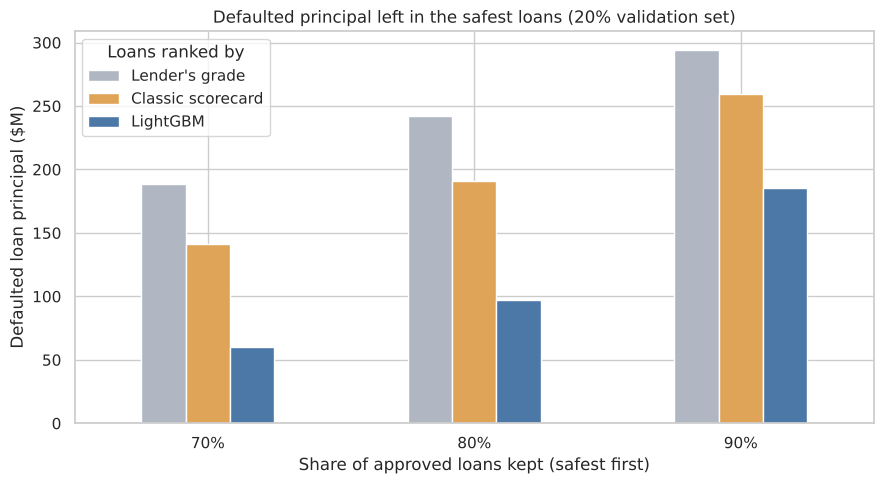

In [14]:
pivot = impact.pivot(index="share_kept", columns="ranked_by", values="defaulted_principal_$M")[list(rankers)]
pivot.plot(kind="bar", figsize=(9, 5), color=["#B0B7C3", "#E0A458", "#4C78A8"], rot=0)
plt.title("Defaulted principal left in the safest loans (20% validation set)")
plt.ylabel("Defaulted loan principal ($M)")
plt.xlabel("Share of approved loans kept (safest first)")
plt.legend(title="Loans ranked by")
plt.tight_layout()
plt.savefig(FIG_DIR / "business_impact.png", dpi=120)
plt.show()

**How to read**
- The validation loans are ranked from safest to riskiest by each method, and the safest 70% / 80% / 90% are kept.
- `defaulted_principal_$M` = total loan amount of the kept loans that were **not** repaid. This is principal at risk, not final loss (lenders recover part of it), and the data is synthetic — the direction matters more than the exact dollars.

**Interpretation**
- If the lender had kept only the safest **80%** of its approved loans, ranking by its own grade would still leave **$242.0M** of defaulted principal; the classic scorecard **$190.6M**; **LightGBM $97.1M** — about **60% less than the lender's grade**.
- The kept group's default rate falls from **17.0%** (grade) to **6.8%** (LightGBM).
- The gap holds at 70%, 80%, and 90%, so the result does not depend on one particular cut.

## Step 7c · Main drivers of high default risk

LightGBM can split each prediction into the contribution of every feature (`pred_contrib=True`, the same idea as SHAP values).
For a high-risk borrower, the features with the **most negative** contributions are the main drivers of that borrower's risk.

These are **model explanations**, not real decline reasons: every loan here was approved, and an actual adverse-action notice would also need legal review.

In [15]:
# contribution of each feature to each validation borrower's score (last column = base value)
contrib = lgbm_val.booster_.predict(X_gbm.loc[val_idx], pred_contrib=True)[:, :-1]
contrib = pd.DataFrame(contrib, columns=X_gbm.columns, index=val_idx)

DRIVER_TEXT = {
    "employment_status": "Employment status: {}",
    "debt_to_income_ratio": "High debt-to-income ratio ({:.2f})",
    "credit_score": "Low credit score ({})",
    "grade_ordinal": "Weak lender risk grade ({})",
    "interest_rate": "High interest rate ({:.1f}%)",
    "annual_income": "Low annual income (${:,.0f})",
    "loan_amount": "Loan amount (${:,.0f})",
    "loan_purpose": "Loan purpose: {}",
    "education_level": "Education level: {}",
    "marital_status": "Marital status: {}",
}


def top_drivers(row_id, n=3):
    row = contrib.loc[row_id]
    worst = row[row < 0].sort_values().head(n).index
    values = X_gbm.loc[row_id]
    return [DRIVER_TEXT[f].format(values[f]) for f in worst]

In [16]:
pd.set_option("display.max_colwidth", None)

# examples: the five validation borrowers with the lowest payback probability
examples = val.sort_values("score_lgbm").head(5).index

example_table = pd.DataFrame({
    "payback_probability": val.loc[examples, "score_lgbm"].round(3),
    "actually_repaid": val.loc[examples, TARGET],
    "top_risk_drivers": [" | ".join(top_drivers(i)) for i in examples],
})
display(example_table)

,payback_probability,actually_repaid,top_risk_drivers
106853,0.001,0,Employment status: Unemployed | High debt-to-income ratio (0.24) | Low credit score (585)
200236,0.001,0,Employment status: Unemployed | High debt-to-income ratio (0.28) | Low credit score (566)
72043,0.001,0,Employment status: Unemployed | High debt-to-income ratio (0.29) | Low credit score (522)
297025,0.001,0,Employment status: Unemployed | High debt-to-income ratio (0.30) | Low credit score (524)
588888,0.001,0,Employment status: Unemployed | High debt-to-income ratio (0.28) | Low credit score (651)


In [17]:
# among the riskiest 10% of borrowers, which feature is the No. 1 driver?
high_risk = val.index[val["score_lgbm"] <= val["score_lgbm"].quantile(0.10)]
first_driver = contrib.loc[high_risk].idxmin(axis=1).value_counts(normalize=True) * 100

display(first_driver.round(1).rename("share_of_riskiest_10%").to_frame())
print(f"{len(high_risk):,} borrowers in the riskiest 10%; "
      f"actual default rate {(val.loc[high_risk, TARGET] == 0).mean():.1%}")

,share_of_riskiest_10%
employment_status,100.0
debt_to_income_ratio,0.0


11,880 borrowers in the riskiest 10%; actual default rate 97.6%


**How to read**
- Each high-risk borrower gets up to three drivers, ranked by how much they pulled the payback score down.
- Gender is not in the model, so it can never appear as a driver.
- This shows the model can give **specific, borrower-level explanations**, which is the kind of transparency US lending rules (ECOA / CFPB Circular 2022-03) expect from complex credit models.

**Interpretation**
- The five riskiest validation borrowers (payback probability ≈ 0.001, all actually defaulted) share the same top three drivers: **unemployed, high DTI (0.24 – 0.30), and low credit score (522 – 651)**.
- Among the riskiest 10% (11,880 borrowers, **97.6% actually defaulted**), employment status is the No. 1 driver for **100%** of them. In the examples above, DTI and credit score come second and third.
- This matches the EDA (only 8% of unemployed borrowers repaid) and the feature importance above, so the explanations are consistent with what the data shows.

## Step 7d · Low / medium / high risk tiers and threshold sensitivity

Borrowers are grouped by predicted payback probability:

- **High risk:** below the lower cutoff
- **Medium risk:** between the two cutoffs
- **Low risk:** at or above the upper cutoff

To choose the cutoffs, imagine using these tiers for **similar future applicants**: low risk = approve, medium = manual review, high = decline. The data has no recovery amounts, profit, or officer decisions, so this uses **stated assumptions**, followed by a sensitivity check. The result is illustrative because of the reject-inference limitation above.

| Assumption | Value | Why |
|---|---|---|
| Loss given default | 60% of the loan amount | rule-of-thumb for unsecured consumer loans |
| Income from a repaid loan | loan amount × interest rate (one year) | rough interest income |
| Cost of one manual review | $50 | officer time |
| Medium-tier capacity | at most 15% of loans | officers cannot review everyone |
| What a review achieves | officer catches 50% of defaults, wrongly declines 10% of good borrowers | a person adds information the model does not have |

In [18]:
ASSUME = {
    "loss_given_default": 0.60,
    "review_cost": 50,
    "max_medium_share": 0.15,
    "review_catch_rate": 0.50,
    "review_false_decline": 0.10,
}

prob = val["score_lgbm"].values
repaid = val[TARGET].values == 1
amount = val["loan_amount"].values
interest = train.loc[val_idx, "interest_rate"].values / 100
income_if_repaid = amount * interest


def net_value(low, high, lgd):
    low_risk = prob >= high
    medium = (prob >= low) & ~low_risk
    income = income_if_repaid[low_risk & repaid].sum() \
        + (1 - ASSUME["review_false_decline"]) * income_if_repaid[medium & repaid].sum()
    loss = (amount * lgd)[low_risk & ~repaid].sum() \
        + (1 - ASSUME["review_catch_rate"]) * (amount * lgd)[medium & ~repaid].sum()
    cost = ASSUME["review_cost"] * medium.sum()
    return income - loss - cost, low_risk.mean(), medium.mean()


def best_cutoffs(lgd, max_medium_share):
    best = None
    for high in np.arange(0.70, 0.99, 0.01):
        for low in np.arange(0.20, high, 0.01):
            value, low_share, medium_share = net_value(low, high, lgd)
            if medium_share <= max_medium_share and (best is None or value > best["net_$M"] * 1e6):
                best = {
                    "high_risk_below": round(low, 2),
                    "low_risk_at_or_above": round(high, 2),
                    "low_%": round(low_share * 100, 1),
                    "medium_%": round(medium_share * 100, 1),
                    "high_%": round((1 - low_share - medium_share) * 100, 1),
                    "net_$M": round(value / 1e6, 1),
                }
    return best


best = best_cutoffs(ASSUME["loss_given_default"], ASSUME["max_medium_share"])
print(best)

{'high_risk_below': np.float64(0.77), 'low_risk_at_or_above': np.float64(0.89), 'low_%': np.float64(62.0), 'medium_%': np.float64(14.8), 'high_%': np.float64(23.2), 'net_$M': np.float64(115.5)}


**Interpretation**
- Under the base assumptions (LGD 60%, $50 review, medium tier ≤ 15%), the best cutoffs are:
  - **Low risk:** payback probability **≥ 0.89**
  - **Medium risk:** **0.77 – 0.89**
  - **High risk:** **below 0.77**
- The medium tier uses 14.8% of loans, just under the 15% review capacity.

In [19]:
# the three tiers at the chosen cutoffs: how risky is each one really?
tier = np.where(prob >= best["low_risk_at_or_above"], "Low risk",
                np.where(prob >= best["high_risk_below"], "Medium risk", "High risk"))

tier_table = (
    val.assign(tier=tier, defaulted=val[TARGET] == 0)
    .groupby("tier")
    .agg(loans=("defaulted", "size"), default_rate=("defaulted", "mean"))
    .reindex(["Low risk", "Medium risk", "High risk"])
)
tier_table["share_of_loans_%"] = (tier_table["loans"] / len(val) * 100).round(1)
tier_table["default_rate_%"] = (tier_table["default_rate"] * 100).round(1)
tier_table["share_of_all_defaults_%"] = (
    tier_table["loans"] * tier_table["default_rate"] / (val[TARGET] == 0).sum() * 100
).round(1)

display(tier_table[["loans", "share_of_loans_%", "default_rate_%", "share_of_all_defaults_%"]])

,loans,share_of_loans_%,default_rate_%,share_of_all_defaults_%
tier,,,,
Low risk,73619,62.0,3.7,11.3
Medium risk,17631,14.8,15.4,11.4
High risk,27549,23.2,67.1,77.3


**Interpretation**
- The tiers separate risk clearly: default rate **3.7%** (low) → **15.4%** (medium) → **67.1%** (high).
- The low-risk tier holds **62% of loans but only 11.3% of all defaults**.
- The high-risk tier holds 23% of loans but **77.3% of all defaults**.

In [20]:
# value of the tiers if used for similar future applicants (illustrative)
keep_all = net_value(0, 0, ASSUME["loss_given_default"])[0]
two_tier = best_cutoffs(ASSUME["loss_given_default"], 0.0)

policy = pd.DataFrame([
    {"policy": "Treat every loan the same (approve all)", "net_$M": round(keep_all / 1e6, 1)},
    {"policy": "Two tiers: low / high (no review)", **two_tier},
    {"policy": "Three tiers: low / medium / high", **best},
])
display(policy)

,policy,net_$M,high_risk_below,low_risk_at_or_above,low_%,medium_%,high_%
0,Treat every loan the same (approve all),-42.1,NaN,NaN,NaN,NaN,NaN
1,Two tiers: low / high (no review),107.9,0.81,0.81,74.0,0.0,26.0
2,Three tiers: low / medium / high,115.5,0.77,0.89,62.0,14.8,23.2


**Interpretation**
- Under these assumptions, treating every loan the same gives a net value of **−$42.1M**: losses from the 20% that default outweigh the interest earned.
- Two tiers (no review) turn this into **+$107.9M**; adding a medium tier for manual review adds another **$7.6M**, to **+$115.5M**.
- These dollars depend on the assumptions and the data is synthetic, so they show the direction, not a real bank's profit. Because every loan here was approved, the tiers illustrate how the scores could be used for similar future applicants.

In [21]:
# sensitivity: how the cutoffs move when the assumptions change
rows = []
for lgd in [0.40, 0.60, 0.80]:
    for cap in [0.10, 0.15, 0.20]:
        rows.append({"loss_given_default": lgd, "max_medium_share": cap, **best_cutoffs(lgd, cap)})

sensitivity = pd.DataFrame(rows)
display(sensitivity)
sensitivity.to_csv(FIG_DIR / "tier_sensitivity.csv", index=False)

,loss_given_default,max_medium_share,high_risk_below,low_risk_at_or_above,low_%,medium_%,high_%,net_$M
0,0.4,0.10,0.69,0.84,70.7,9.8,19.5,127.7
1,0.4,0.15,0.68,0.87,66.0,14.8,19.2,128.8
2,0.4,0.20,0.65,0.89,62.0,19.9,18.1,129.7
3,0.6,0.10,0.76,0.86,67.7,9.7,22.6,113.3
4,0.6,0.15,0.77,0.89,62.0,14.8,23.2,115.5
5,0.6,0.20,0.77,0.91,56.8,20.0,23.2,116.9
6,0.8,0.10,0.83,0.89,62.0,10.0,28.0,101.8
7,0.8,0.15,0.81,0.90,59.5,14.4,26.0,103.8
8,0.8,0.20,0.82,0.92,53.8,19.3,27.0,105.8


**Interpretation**
- The **high-risk cutoff moves with the loss given default**: about 0.65 – 0.69 when a default costs 40%, 0.76 – 0.77 at 60%, and 0.81 – 0.83 at 80%. When defaults cost more, the lender should flag more loans as high risk.
- The **low-risk cutoff moves with review capacity**: from about 0.84 – 0.86 (10% capacity) to 0.89 – 0.92 (20%). More officers means more loans can go to the medium tier.
- Net value stays positive in all nine scenarios ($101.8M – $129.7M), so the three-tier design holds even when the assumptions change; only the exact cutoffs shift.

## Step 8 · Kaggle submission

In [22]:
X_test = test[GBM_NUM + GBM_CAT].copy()
for col in GBM_CAT:
    X_test[col] = pd.Categorical(X_test[col], categories=X_gbm[col].cat.categories)

submission = pd.DataFrame({
    "id": test["id"],
    TARGET: lgbm.predict_proba(X_test)[:, 1],
})

submission.to_csv(DATA_DIR / "submission.csv", index=False)
print(submission.shape)
submission.head()

(254569, 2)


,id,loan_paid_back
0,593994,0.910861
1,593995,0.981116
2,593996,0.470214
3,593997,0.926211
4,593998,0.971663


**Interpretation**
- The final LightGBM model is fitted on all training rows, then predicts a **probability** of payback for every test id.
- Probabilities (not 0/1 labels) are submitted because Kaggle scores with ROC AUC, which measures ranking.
- Test categories use the same category list as training, so the encoding is identical.